# Bank Marketing — Data Understanding & EDA

## 1. Introduction

This notebook inspects the UCI Bank Marketing dataset, defines the
prediction-time feature policy, establishes the chronological split, and
explores the training data.

- **Target:** `y`
- **Prediction time:** immediately before a planned marketing contact
- **Modeling objective:** rank records by likelihood of term-deposit subscription
- **Scope:** data understanding only; no preprocessing or model training

## 2. Data Loading & Inspection

Load the source CSV in its original row order and inspect its structure.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "bank-additional"
    / "bank-additional-full.csv"
)

df = pd.read_csv(RAW_DATA_PATH, sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [3]:
pd.DataFrame(
    {
        "rows": [len(df)],
        "columns": [df.shape[1]],
        "numeric_columns": [df.select_dtypes(include="number").shape[1]],
        "categorical_columns": [df.select_dtypes(exclude="number").shape[1]],
    }
)

,rows,columns,numeric_columns,categorical_columns
0,41188,21,10,11


The dataset contains 41,188 records, 20 input variables, and the binary target
`y`. The raw schema includes `duration`, which is unavailable at prediction
time and must not be used for modeling.

## 3. Data Leakage & Splitting Strategy

### 3.1 Feature Definition

All predictors except `duration` are treated as available immediately before
the planned contact. `duration` is known only after the contact ends, so it is
excluded to prevent target leakage.

In [4]:
target = "y"
excluded_features = ["duration"]
modeling_features = [
    column for column in df.columns
    if column not in [target, *excluded_features]
]

numeric_predictors = (
    df[modeling_features].select_dtypes(include="number").columns.tolist()
)
categorical_predictors = (
    df[modeling_features].select_dtypes(exclude="number").columns.tolist()
)

pd.Series(modeling_features, name="modeling_feature")

0                age
1                job
2            marital
3          education
4            default
5            housing
6               loan
7            contact
8              month
9        day_of_week
10          campaign
11             pdays
12          previous
13          poutcome
14      emp.var.rate
15    cons.price.idx
16     cons.conf.idx
17         euribor3m
18       nr.employed
Name: modeling_feature, dtype: str

### 3.2 Chronological Split

The source row order is treated as chronological. The first 70% is Train, the
next 20% is Validation, and the final 10% is Test. The split is not shuffled or
stratified, and `month` or `day_of_week` is not used to reconstruct dates.

Development EDA uses Train. Validation is reserved for model selection, and
Test remains frozen for final evaluation. A prior aggregate inspection of the
Test target is disclosed in the project documentation.

In [5]:
n_rows = len(df)
train_end = int(n_rows * 0.70)
valid_end = int(n_rows * 0.90)

train_df = df.iloc[:train_end].copy()
valid_df = df.iloc[train_end:valid_end].copy()
test_df = df.iloc[valid_end:].copy()

split_summary = pd.DataFrame(
    {
        "rows": [len(train_df), len(valid_df), len(test_df)],
        "proportion": [
            len(train_df) / n_rows,
            len(valid_df) / n_rows,
            len(test_df) / n_rows,
        ],
        "first_row": [train_df.index.min(), valid_df.index.min(), test_df.index.min()],
        "last_row": [train_df.index.max(), valid_df.index.max(), test_df.index.max()],
    },
    index=["Train", "Validation", "Test"],
)

split_summary

,rows,proportion,first_row,last_row
Train,28831,0.699985,0,28830
Validation,8238,0.200010,28831,37068
Test,4119,0.100005,37069,41187


In [6]:
development_target_summary = pd.DataFrame(
    {
        "rows": [len(train_df), len(valid_df)],
        "subscribers": [
            train_df[target].eq("yes").sum(),
            valid_df[target].eq("yes").sum(),
        ],
        "subscription_rate": [
            train_df[target].eq("yes").mean(),
            valid_df[target].eq("yes").mean(),
        ],
    },
    index=["Train", "Validation"],
)

development_target_summary

,rows,subscribers,subscription_rate
Train,28831,1606,0.055704
Validation,8238,1142,0.138626


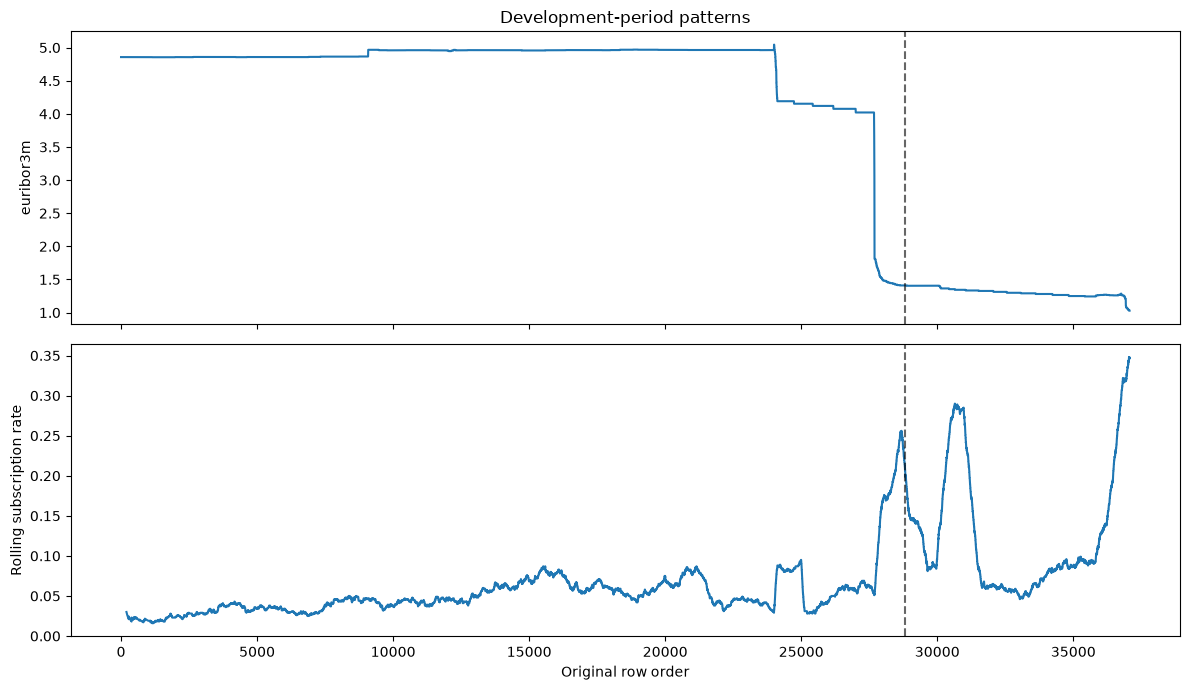

In [7]:
development_df = df.iloc[:valid_end]
rolling_subscription_rate = (
    development_df[target]
    .eq("yes")
    .rolling(window=1_000, min_periods=200)
    .mean()
)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(development_df.index, development_df["euribor3m"])
axes[1].plot(development_df.index, rolling_subscription_rate)

for ax in axes:
    ax.axvline(train_end - 0.5, color="black", linestyle="--", alpha=0.6)

axes[0].set(title="Development-period patterns", ylabel="euribor3m")
axes[1].set(xlabel="Original row order", ylabel="Rolling subscription rate")
plt.tight_layout()
plt.show()

Train has a 5.57% subscription rate, while Validation reaches 13.86%—about
2.5 times the Train prevalence. `euribor3m` and the rolling subscription rate
also change across the boundary. This indicates meaningful temporal and
prevalence shift, so Validation performance should be interpreted as
later-period generalization rather than as an identically distributed sample.

The shift also means prevalence-sensitive metrics such as Average Precision
and Precision@K should always be reported with the evaluated split's positive
rate. Random splitting would obscure this deployment-relevant difficulty.

## 4. Exploratory Data Analysis

### 4.1 Data Quality

Inspect missing values, explicit `"unknown"` categories, exact duplicates, and
the sentinel structure of `pdays` using Train only.

In [8]:
data_quality_summary = pd.Series(
    {
        "missing_values": train_df.isna().sum().sum(),
        "exact_duplicate_rows": train_df.duplicated().sum(),
    },
    name="count",
)

unknown_counts = train_df[categorical_predictors].eq("unknown").sum()
unknown_summary = pd.DataFrame(
    {
        "count": unknown_counts,
        "rate": unknown_counts / len(train_df),
    }
).query("count > 0").sort_values("rate", ascending=False)

display(data_quality_summary)
unknown_summary

missing_values          0
exact_duplicate_rows    9
Name: count, dtype: int64

,count,rate
default,7302,0.253269
education,1183,0.041032
housing,694,0.024071
loan,694,0.024071
job,249,0.008637
marital,49,0.001700


In [9]:
pdays_non_sentinel = train_df.loc[train_df["pdays"].ne(999), "pdays"]

pd.Series(
    {
        "pdays_999_count": train_df["pdays"].eq(999).sum(),
        "pdays_999_rate": train_df["pdays"].eq(999).mean(),
        "non_999_count": len(pdays_non_sentinel),
        "non_999_min": pdays_non_sentinel.min(),
        "non_999_median": pdays_non_sentinel.median(),
        "non_999_max": pdays_non_sentinel.max(),
    },
    name="value",
)

pdays_999_count    28778.000000
pdays_999_rate         0.998162
non_999_count         53.000000
non_999_min            0.000000
non_999_median         5.000000
non_999_max           11.000000
Name: value, dtype: float64

Train has no pandas-recognized missing values, but several categorical features
contain the explicit value `"unknown"`. The largest is `default` at 25.33%, so
silently treating it as a null or dropping those records would remove a
substantial part of the data. It will remain an observed category.

Nine exact duplicate rows are retained because the dataset has no customer ID
or complete timestamp with which to establish erroneous duplication.

`pdays = 999` occurs in 99.82% of Train. The remaining 53 observations range
from 0 to 11 days, so `999` is not a plausible point on the same elapsed-day
scale. The preprocessing representation should explicitly separate whether a
previous contact was recorded from the elapsed days for contacted records.

### 4.2 Target Distribution

Inspect class balance in Train. Accuracy alone is not informative for this
ranking problem because the positive class is uncommon.

In [10]:
target_counts = train_df[target].value_counts().reindex(["no", "yes"])
target_summary = pd.DataFrame(
    {
        "count": target_counts,
        "proportion": target_counts / len(train_df),
    }
)

target_summary

,count,proportion
y,,
no,27225,0.944296
yes,1606,0.055704


Train contains 1,606 subscribers, a 5.57% positive rate. An always-`no`
prediction would be 94.43% accurate while identifying no subscribers, so
accuracy is not suitable as the main criterion. Model development will
prioritize Average Precision and Top-K ranking metrics.

### 4.3 Feature Distributions

Summarize numerical scales and categorical frequencies. `pdays` is excluded
from the ordinary numerical summary because its sentinel was inspected above.

In [11]:
distribution_features = [
    feature for feature in numeric_predictors if feature != "pdays"
]

numeric_summary = (
    train_df[distribution_features]
    .describe(percentiles=[0.50, 0.95, 0.99])
    .T[["min", "50%", "95%", "99%", "max"]]
)
numeric_summary["unique_values"] = train_df[distribution_features].nunique()
numeric_summary["zero_share"] = train_df[distribution_features].eq(0).mean()

numeric_summary

,min,50%,95%,99%,max,unique_values,zero_share
age,18.000,39.000,57.000,59.000,95.000,63,0.000000
campaign,1.000,2.000,8.000,17.000,56.000,42,0.000000
previous,0.000,0.000,0.000,1.000,3.000,4,0.965246
emp.var.rate,-1.800,1.400,1.400,1.400,1.400,5,0.000000
cons.price.idx,92.756,93.918,94.465,94.465,94.465,9,0.000000
cons.conf.idx,-50.000,-41.800,-36.100,-36.100,-36.100,9,0.000000
euribor3m,1.410,4.957,4.967,4.968,5.045,93,0.000000
nr.employed,5099.100,5228.100,5228.100,5228.100,5228.100,5,0.000000


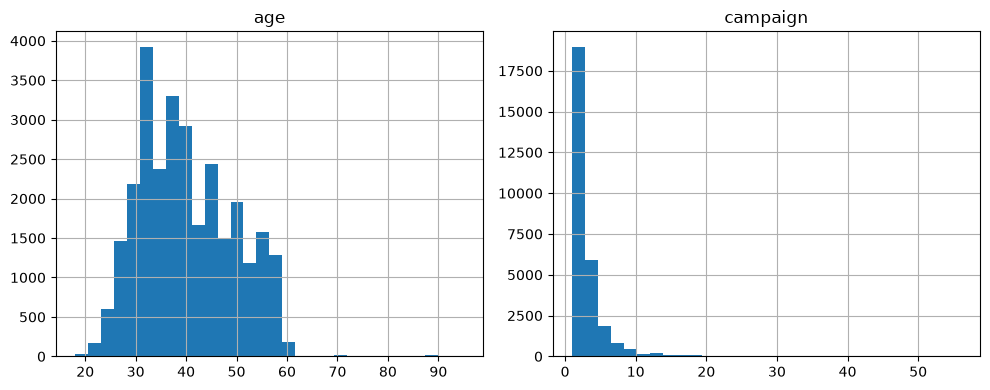

In [12]:
train_df[["age", "campaign"]].hist(bins=30, figsize=(10, 4))
plt.tight_layout()
plt.show()

In [13]:
categorical_summary = pd.DataFrame(
    {
        "n_categories": train_df[categorical_predictors].nunique(),
        "top_category": train_df[categorical_predictors].mode().iloc[0],
        "top_share": train_df[categorical_predictors].apply(
            lambda series: series.value_counts(normalize=True).iloc[0]
        ),
        "smallest_category_count": train_df[categorical_predictors].apply(
            lambda series: series.value_counts().min()
        ),
    }
).sort_values("n_categories", ascending=False)

categorical_summary

,n_categories,top_category,top_share,smallest_category_count
job,12,admin.,0.246505,237
month,9,may,0.269259,10
education,8,university.degree,0.289445,14
day_of_week,5,thu,0.211196,5270
marital,4,married,0.631404,49
default,3,no,0.746627,3
loan,3,no,0.824599,694
housing,3,yes,0.508099,694
poutcome,3,nonexistent,0.965246,50
contact,2,cellular,0.521591,13793


`campaign` is right-skewed: its median is 2 contacts, the 95th percentile is 8,
and the maximum is 56. `previous` is zero for 96.52% of Train. These variables
are retained as recorded; transformations should be justified by Validation
rather than by skewness alone.

The macroeconomic features have few unique values and behave more like
period-level signals than continuously varying customer attributes. Several
categorical levels are also rare. One-hot encoding should therefore tolerate
levels absent from Train, while rare groups should not be interpreted from
their raw rates without considering sample size.

### 4.4 Feature-Target Relationships

The following summaries describe associations in Train. They are not causal
effects or model-based feature importance.

In [14]:
train_analysis = train_df.assign(y_yes=train_df[target].eq("yes").astype(int))
selected_categorical = ["job", "contact", "month", "poutcome"]

categorical_target_summary = pd.concat(
    [
        train_analysis.groupby(feature, observed=True)["y_yes"]
        .agg(count="size", subscribers="sum", subscription_rate="mean")
        .reset_index(names="category")
        .assign(feature=feature)
        for feature in selected_categorical
    ],
    ignore_index=True,
).set_index(["feature", "category"])

categorical_target_summary

count  subscribers  subscription_rate
feature  category                                            
job      admin.          7107          416           0.058534
         blue-collar     6705          337           0.050261
         entrepreneur    1105           60           0.054299
         housemaid        838           30           0.035800
         management      2096          127           0.060592
         retired          879           81           0.092150
         self-employed   1043           62           0.059444
         services        2826          143           0.050602
         student          237           33           0.139241
         technician      5054          271           0.053621
         unemployed       692           33           0.047688
         unknown          249           13           0.052209
contact  cellular       15038         1051           0.069890
         telephone      13793          555           0.040238
month    apr              859          141           0.164144
         aug             5175          271           0.052367
         dec               10            1           0.100000
         jul             6685          407           0.060883
         jun             4374          188           0.042981
         mar              282          126           0.446809
         may             7763          240           0.030916
         nov             3616          190           0.052544
         oct               67           42           0.626866
poutcome failure          952           56           0.058824
         nonexistent    27829         1543           0.055446
         success           50            7           0.140000

In [15]:
selected_numeric = ["age", "campaign", "previous", "euribor3m", "nr.employed"]
numeric_target_summary = (
    train_analysis.groupby(target)[selected_numeric]
    .agg(["mean", "median"])
    .T
)

pdays_target_summary = (
    train_analysis
    .assign(pdays_is_999=train_analysis["pdays"].eq(999))
    .groupby("pdays_is_999")["y_yes"]
    .agg(count="size", subscribers="sum", subscription_rate="mean")
)

display(numeric_target_summary)
pdays_target_summary

y                            no          yes
age         mean      40.218329    39.485056
            median    39.000000    37.000000
campaign    mean       2.785308     2.479452
            median     2.000000     2.000000
previous    mean       0.035556     0.041719
            median     0.000000     0.000000
euribor3m   mean       4.709733     4.274133
            median     4.957000     4.957000
nr.employed mean    5209.595581  5196.411083
            median  5228.100000  5228.100000

,count,subscribers,subscription_rate
pdays_is_999,,,
False,53,8,0.150943
True,28778,1598,0.055529


Several descriptive differences are visible in Train. The subscription rate is
6.99% for `cellular` and 4.02% for `telephone`; students have a 13.92% rate, but
only 237 observations. Month-level rates vary even more, partly reflecting the
time-ordered economic conditions rather than a standalone seasonal effect.

Subscribers have lower mean `euribor3m` and `nr.employed` values, again linking
the target to the economic period. Records with `pdays != 999` have a 15.09%
subscription rate versus 5.55% for `pdays = 999`, but the former group contains
only 53 records. These are hypotheses for modeling, not causal effects or
stable effects established by EDA.

### 4.5 Feature Relationships

Inspect correlations among macroeconomic predictors and the joint structure of
previous-campaign history variables.

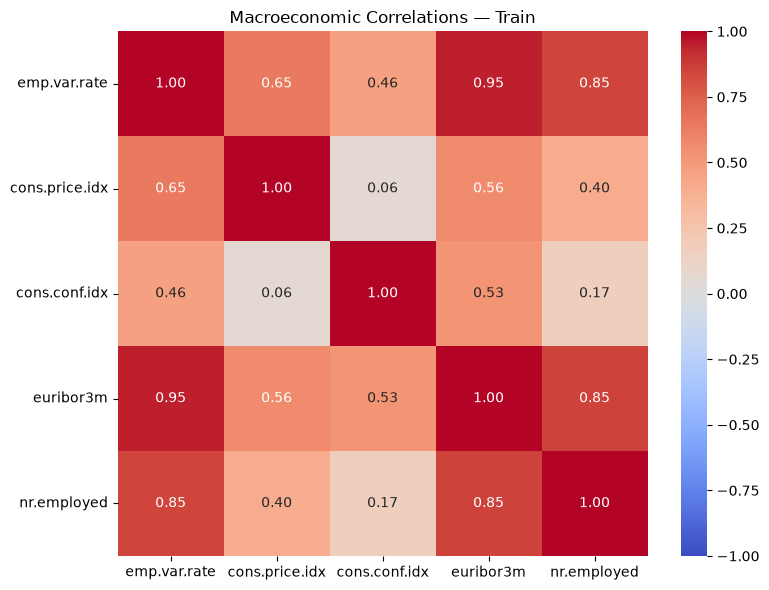

In [16]:
macro_features = [
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
]

plt.figure(figsize=(8, 6))
sns.heatmap(
    train_df[macro_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Macroeconomic Correlations — Train")
plt.tight_layout()
plt.show()

In [17]:
pd.crosstab(
    index=train_df["poutcome"],
    columns=[train_df["previous"].gt(0), train_df["pdays"].eq(999)],
    rownames=["poutcome"],
    colnames=["previous > 0", "pdays = 999"],
)

previous > 0  False True       
pdays = 999   True  False True 
poutcome                       
failure           0     3   949
nonexistent   27829     0     0
success           0    50     0

## 5. Findings & Decisions

### Data and Evaluation

- Train contains 28,831 records and a 5.57% positive rate; Validation contains
  8,238 records and a 13.86% positive rate.
- Preserve the chronological 70/20/10 split because later periods differ
  materially from Train.
- Use Train for fitting and EDA, Validation for model selection, and Test only
  for final evaluation.
- Report prevalence with Average Precision and Top-K metrics; accuracy alone is
  misleading under the observed class imbalance.

### Feature and Preprocessing Decisions

- Exclude `duration`; retain the other 19 raw prediction-time predictors.
- Keep `"unknown"` as an explicit category and retain exact duplicates because
  erroneous records cannot be identified from the available fields.
- Do not remove skewed, rare, or correlated features solely from EDA.
- Treat `pdays = 999` as a sentinel rather than an elapsed-day value. Derive:
  - `pdays_previously_contacted = 1` when `pdays != 999`, otherwise `0`.
  - `pdays_elapsed = pdays` when previously contacted, otherwise `0`.
- Do not pass raw `pdays` directly to the numerical scaler.

### Interpretation and Limitations

Macroeconomic predictors are strongly related; for example, `emp.var.rate` and
`euribor3m` have a Train correlation of about 0.95. This can make individual
linear coefficients unstable even when the combined signal remains useful.

The history fields are related but not interchangeable. In particular, 949
records have `previous > 0` while `pdays = 999`, so neither field should be
used to overwrite the other. The derived `pdays` features represent only the
published sentinel semantics.

The dataset lacks unique customer identifiers and complete timestamps, so
client overlap, exact calendar boundaries, and point-in-time availability of
macroeconomic values cannot be fully verified. All observed relationships are
associational, not evidence of causal marketing effects.